## Import

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from catboost import CatBoostClassifier

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("Import berhasil.")

Import berhasil.


## Load Model dan Data Test

In [2]:
MODEL_PATH = Path(
    "../models/catboost/catboost_final.cbm"
)

TEST_FEATURES_PATH = Path(
    "../outputs/feature_integration/test_features.csv"
)

TEST_TARGET_PATH = Path(
    "../outputs/feature_integration/test_target.csv"
)

model = CatBoostClassifier()

model.load_model(
    MODEL_PATH
)

X_test = pd.read_csv(
    TEST_FEATURES_PATH
)

test_target_df = pd.read_csv(
    TEST_TARGET_PATH
)

# Ambil target
if "dev_status" in test_target_df.columns:
    y_test = test_target_df["dev_status"]
else:
    y_test = test_target_df.iloc[:, 0]

print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

X_test : (16000, 107)
y_test : (16000,)


## Final Leakage Check

In [3]:
assert len(X_test) == 16000
assert len(y_test) == 16000

assert "dev_status" not in X_test.columns

assert X_test.isna().sum().sum() == 0
assert y_test.isna().sum() == 0

print("===== FINAL TEST CHECK =====")
print("Jumlah TEST :", len(X_test))
print("Jumlah fitur:", X_test.shape[1])
print("Target dalam X:", "dev_status" in X_test.columns)
print("Missing X:", X_test.isna().sum().sum())
print("Missing y:", y_test.isna().sum())

print("\nDistribusi target TEST:")
print(y_test.value_counts())

===== FINAL TEST CHECK =====
Jumlah TEST : 16000
Jumlah fitur: 107
Target dalam X: False
Missing X: 0
Missing y: 0

Distribusi target TEST:
dev_status
suspect    12796
normal      3204
Name: count, dtype: int64


## Prediksi TEST

In [4]:
y_pred = model.predict(
    X_test
).ravel()

print("Prediksi selesai.")
print("Jumlah prediksi:", len(y_pred))

assert len(y_pred) == 16000

Prediksi selesai.
Jumlah prediksi: 16000


## Accuracy, Precision, Recall, F1

In [5]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    pos_label="suspect",
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    pos_label="suspect",
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    pos_label="suspect",
    zero_division=0
)

print("===== HASIL EVLASUASI FINAL =====")

print(
    f"Accuracy : {accuracy:.4f}"
)

print(
    f"Precision: {precision:.4f}"
)

print(
    f"Recall   : {recall:.4f}"
)

print(
    f"F1-Score : {f1:.4f}"
)

===== HASIL EVLASUASI FINAL =====
Accuracy : 0.9738
Precision: 0.9756
Recall   : 0.9920
F1-Score : 0.9837


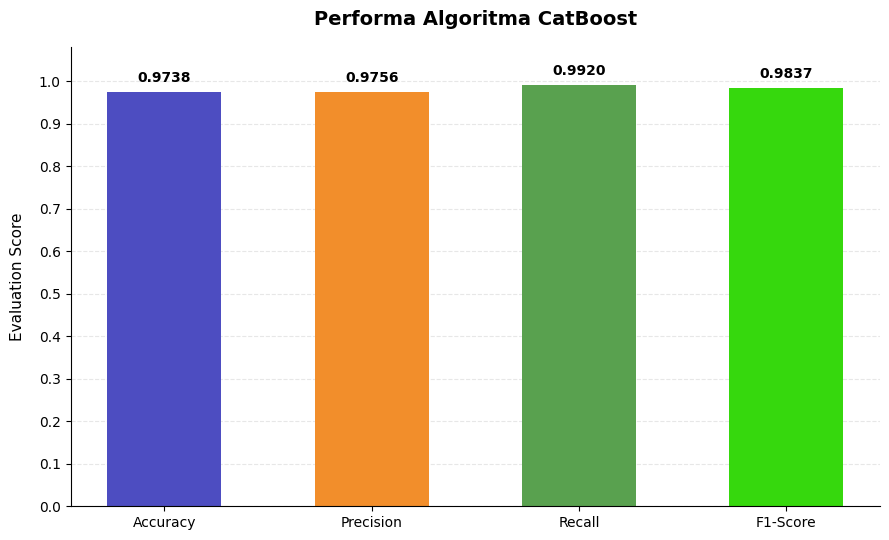

In [6]:

# Visualisasi Hasil Evaluasi Klasifikasi CatBoost

import matplotlib.pyplot as plt
import numpy as np

# Data hasil evaluasi
metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

metric_values = [
    accuracy,
    precision,
    recall,
    f1
]

x = np.arange(len(metric_names))

# Membuat visualisasi
fig, ax = plt.subplots(figsize=(9, 5.5))

bars = ax.bar(
    x,
    metric_values,
    width=0.55,
    color=["#4D4DC1", "#F28E2B", "#59A14F", "#36D80D"]
)

# Judul dan label
ax.set_title(
    "Performa Algoritma CatBoost",
    fontsize=14,
    fontweight="bold",
    pad=16
)

ax.set_ylabel(
    "Evaluation Score",
    fontsize=11,
    labelpad=10
)

ax.set_xticks(x)
ax.set_xticklabels(
    metric_names,
    fontsize=10
)

# Skala sumbu Y
ax.set_ylim(0, 1.08)
ax.set_yticks(np.arange(0, 1.01, 0.1))

# Menampilkan nilai pada setiap batang
ax.bar_label(
    bars,
    labels=[f"{value:.4f}" for value in metric_values],
    padding=5,
    fontsize=10,
    fontweight="bold"
)

# Tampilan grid
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

# Merapikan tampilan garis grafik
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

fig.tight_layout()

# Menyimpan visualisasi
plt.savefig(
    "../outputs/figures/final_test_metrics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## Confusion Matrix

In [7]:
LABELS = [
    "normal",
    "suspect"
]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=LABELS
)

cm_df = pd.DataFrame(
    cm,
    index=[
        "Actual normal",
        "Actual suspect"
    ],
    columns=[
        "Pred normal",
        "Pred suspect"
    ]
)

display(cm_df)

,Pred normal,Pred suspect
Actual normal,2886,318
Actual suspect,102,12694


## Classification Report

In [8]:
report_dict = classification_report(
    y_test,
    y_pred,
    labels=LABELS,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(
    report_dict
).T

display(
    report_df
)

,precision,recall,f1-score,support
normal,0.965863,0.900749,0.932171,3204.00000
suspect,0.975561,0.992029,0.983726,12796.00000
accuracy,0.973750,0.973750,0.973750,0.97375
macro avg,0.970712,0.946389,0.957948,16000.00000
weighted avg,0.973619,0.973750,0.973402,16000.00000


## Visualisasi Confusion Matrix

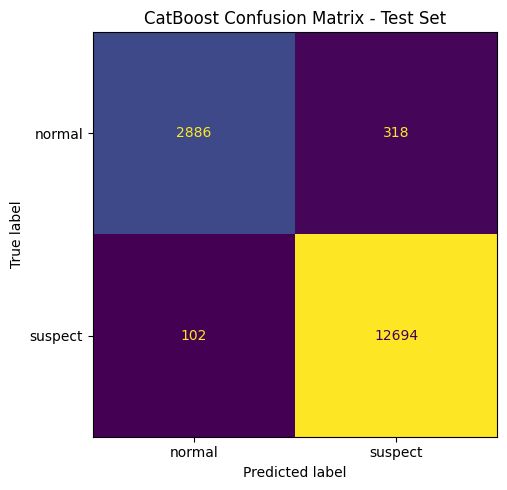

In [9]:
FIGURE_DIR = Path(
    "../outputs/figures"
)

METRICS_DIR = Path(
    "../outputs/metrics"
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

METRICS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

fig, ax = plt.subplots(
    figsize=(6, 5)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=LABELS
)

disp.plot(
    ax=ax,
    values_format="d",
    colorbar=False
)

ax.set_title(
    "CatBoost Confusion Matrix - Test Set"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR /
    "catboost_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Feature Importance

In [10]:

# Feature Importance — 7 Fitur Asli

feature_importance = model.get_feature_importance()

# Gunakan nama fitur sesuai urutan fitur pada model
feature_names = model.feature_names_

feature_importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": feature_importance
})

# Daftar 7 fitur asli
ORIGINAL_FEATURES = [
    "weight",
    "height",
    "age",
    "gross_motor",
    "fine_motor_adaptive",
    "language",
    "personal_social"
]

# Pastikan seluruh fitur asli tersedia
assert all(
    feature in feature_importance_df["feature"].values
    for feature in ORIGINAL_FEATURES
), "Ada fitur asli yang tidak ditemukan dalam model."

# Ambil hanya 7 fitur asli
original_feature_importance_df = (
    feature_importance_df[
        feature_importance_df["feature"].isin(
            ORIGINAL_FEATURES
        )
    ]
    .sort_values(
        by="importance",
        ascending=False
    )
    .reset_index(drop=True)
)

print("Feature Importance — 7 Fitur Asli")

display(
    original_feature_importance_df.round(6)
)


Feature Importance — 7 Fitur Asli


,feature,importance
0,language,24.222323
1,gross_motor,21.880227
2,fine_motor_adaptive,21.248969
3,personal_social,20.825301
4,age,0.012848
5,weight,0.010096
6,height,0.000000


## Visualisasi Feature Importance

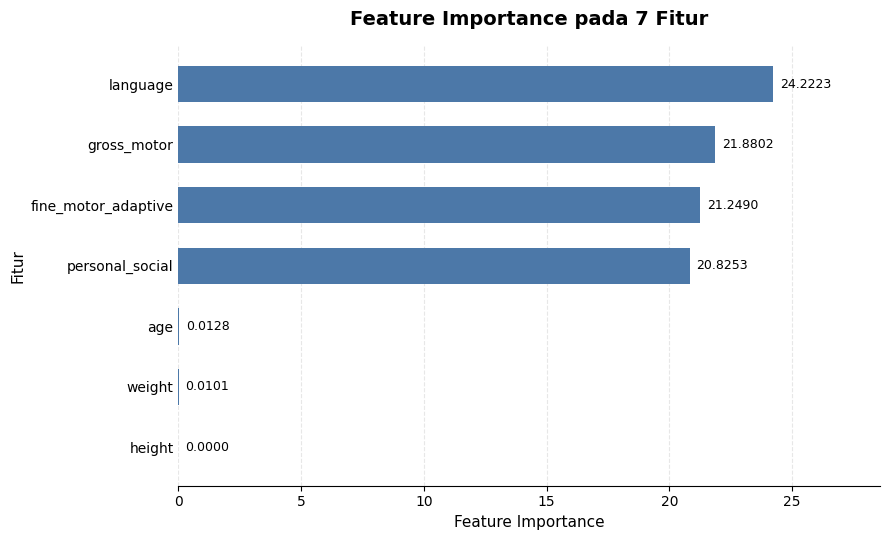

In [11]:

# Visualisasi Feature Importance — 7 Fitur Asli

plot_df = (
    original_feature_importance_df
    .sort_values(
        by="importance",
        ascending=True
    )
)

fig, ax = plt.subplots(figsize=(9, 5.5))

bars = ax.barh(
    plot_df["feature"],
    plot_df["importance"],
    color="#4C78A8",
    height=0.6
)

ax.set_title(
    "Feature Importance pada 7 Fitur",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Feature Importance",
    fontsize=11
)

ax.set_ylabel(
    "Fitur",
    fontsize=11
)

ax.bar_label(
    bars,
    fmt="%.4f",
    padding=5,
    fontsize=9
)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.tick_params(
    axis="y",
    length=0,
    labelsize=10
)

ax.set_xlim(
    0,
    plot_df["importance"].max() * 1.18
)

fig.tight_layout()

plt.savefig(
    FIGURE_DIR / "catboost_feature_importance_original.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## Simpan Hasil Evaluasi

In [12]:
metrics = {
    "test_samples": int(len(y_test)),
    "accuracy": float(accuracy),
    "precision": float(precision),
    "recall": float(recall),
    "f1_score": float(f1),
    "positive_class": "suspect",
    "evaluation_set": "20% test set",
    "test_samples": 16000
}

with open(
    METRICS_DIR /
    "catboost_test_metrics.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metrics,
        f,
        indent=4
    )

cm_df.to_csv(
    METRICS_DIR /
    "catboost_confusion_matrix.csv"
)

report_df.to_csv(
    METRICS_DIR /
    "catboost_classification_report.csv"
)

feature_importance_df.to_csv(
    METRICS_DIR /
    "catboost_feature_importance.csv",
    index=False
)

print("✅ Semua hasil evaluasi tersimpan.")

✅ Semua hasil evaluasi tersimpan.


## Final Summary

In [13]:
print("=" * 50)
print("CHECKPOINT 8 — FINAL EVALUATION")
print("=" * 50)

print("\nDataset:")
print("TRAIN :", 64000)
print("TEST  :", 16000)

print("\nModel:")
print("CatBoost + KGE")
print("Features:", X_test.shape[1])

print("\nFinal Test Metrics:")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")

print("\nLeakage Check:")
print("✅ TEST hanya digunakan pada tahap evaluasi")
print("✅ TEST tidak digunakan Grid Search")
print("✅ TEST tidak digunakan memilih parameter")
print("✅ dev_status tidak terdapat pada X_test")
print("✅ Model final berasal dari TRAIN")

print("\n✅ CHECKPOINT 8 — EVALUATION SELESAI")

CHECKPOINT 8 — FINAL EVALUATION

Dataset:
TRAIN : 64000
TEST  : 16000

Model:
CatBoost + KGE
Features: 107

Final Test Metrics:
Accuracy : 0.9738
Precision: 0.9756
Recall   : 0.9920
F1-Score : 0.9837

Leakage Check:
✅ TEST hanya digunakan pada tahap evaluasi
✅ TEST tidak digunakan Grid Search
✅ TEST tidak digunakan memilih parameter
✅ dev_status tidak terdapat pada X_test
✅ Model final berasal dari TRAIN

✅ CHECKPOINT 8 — EVALUATION SELESAI


## Relationship Analysis

In [14]:
import pickle
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt

TRANSE_PATH = Path(
    "../models/transe/transe_model_full_train.pkl"
)

RELATIONS_PATH = Path(
    "../outputs/kg_relations.txt"
)

with open(TRANSE_PATH, "rb") as f:
    transe_model = pickle.load(f)

# Ambil seluruh relation embedding dari model TransE
relation_embeddings = (
    transe_model.relation_representations[0]()
    .detach()
    .cpu()
    .numpy()
)

print("Relation embedding shape:", relation_embeddings.shape)

# Baca nama relation sesuai urutan ID relation pada KG
with open(RELATIONS_PATH, "r", encoding="utf-8") as f:
    relations = [line.strip() for line in f if line.strip()]

print("Jumlah relations:", len(relations))

assert relation_embeddings.shape[0] == len(relations)

relation_embedding_df = pd.DataFrame(
    relation_embeddings,
    index=relations
)

display(relation_embedding_df)

Relation embedding shape: (7, 100)
Jumlah relations: 7


,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
has_age,-0.092854,0.103491,-0.023355,-0.037471,-0.020725,0.054377,0.113876,-0.063494,0.060622,-0.050196,...,-0.049349,0.090644,0.045641,-0.004916,-0.049317,0.091137,-0.073414,-0.094564,-0.084984,-0.054510
has_fine_motor_adaptive,0.119091,0.023664,-0.051740,-0.084182,0.104674,0.096100,0.081769,0.071095,-0.091599,-0.085735,...,-0.042795,-0.047746,-0.077310,0.048620,0.057196,0.097666,-0.080522,-0.127486,-0.016156,-0.099187
has_gross_motor,-0.051574,0.103876,-0.026718,0.061555,-0.059875,-0.029638,0.105853,-0.121427,0.084827,-0.117094,...,0.095555,0.083460,-0.095291,-0.093461,0.013957,0.117384,-0.090953,0.001280,-0.081399,-0.083036
has_height,0.011270,0.090551,0.036988,0.010875,0.043808,-0.045645,0.107620,-0.087612,0.066666,-0.054933,...,-0.056194,0.057910,-0.056989,0.073333,-0.068313,0.091340,-0.085240,-0.073433,-0.083062,-0.029115
has_language,-0.087211,0.070222,0.017627,-0.072860,0.101950,-0.056234,0.060998,0.050416,0.083865,-0.088500,...,-0.096433,-0.054819,-0.052935,0.101170,0.025880,0.115490,-0.047905,-0.119002,0.045040,0.011019
has_personal_social,-0.065226,0.134750,0.074373,-0.056966,-0.032977,0.072630,0.009001,-0.081571,0.091665,-0.059183,...,0.025081,0.101015,0.054528,0.081255,-0.076866,0.084153,-0.148543,-0.013989,0.054494,-0.042683
has_weight,-0.065871,0.106250,0.047823,0.001794,0.014756,0.086898,0.072526,-0.050644,0.057684,-0.075760,...,-0.032047,0.089587,0.048518,0.055790,0.059915,0.120122,-0.117205,-0.042553,-0.104686,0.042903


In [15]:
similarity_matrix = cosine_similarity(
    relation_embeddings
)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=relations,
    columns=relations
)

display(
    similarity_df.round(4)
)

,has_age,has_fine_motor_adaptive,has_gross_motor,has_height,has_language,has_personal_social,has_weight
has_age,1.0000,0.2851,0.5421,0.6499,0.2402,0.5022,0.5666
has_fine_motor_adaptive,0.2851,1.0000,0.1502,0.4199,0.1419,0.1685,0.3430
has_gross_motor,0.5421,0.1502,1.0000,0.5235,0.1403,0.3967,0.4973
has_height,0.6499,0.4199,0.5235,1.0000,0.2653,0.5147,0.5916
has_language,0.2402,0.1419,0.1403,0.2653,1.0000,0.1569,0.1931
has_personal_social,0.5022,0.1685,0.3967,0.5147,0.1569,1.0000,0.6093
has_weight,0.5666,0.3430,0.4973,0.5916,0.1931,0.6093,1.0000


In [16]:
# Relasi yang dianalisis dalam Relationship Analysis
DEVELOPMENT_RELATIONS = [
    "has_weight",
    "has_height",
    "has_age",
    "has_gross_motor",
    "has_fine_motor_adaptive",
    "has_language",
    "has_personal_social"
]

# Nama atribut untuk ditampilkan pada visualisasi
DISPLAY_NAMES = [
    "weight",
    "height",
    "age",
    "gross_motor",
    "fine_motor_adaptive",
    "language",
    "personal_social"
]

# Ambil embedding dari ketujuh relasi
development_embeddings = relation_embedding_df.loc[
    DEVELOPMENT_RELATIONS
].values

# Hitung Cosine Similarity
development_similarity = cosine_similarity(
    development_embeddings
)

development_similarity_df = pd.DataFrame(
    development_similarity,
    index=DISPLAY_NAMES,
    columns=DISPLAY_NAMES
)

display(
    development_similarity_df.round(4)
)

,weight,height,age,gross_motor,fine_motor_adaptive,language,personal_social
weight,1.0000,0.5916,0.5666,0.4973,0.3430,0.1931,0.6093
height,0.5916,1.0000,0.6499,0.5235,0.4199,0.2653,0.5147
age,0.5666,0.6499,1.0000,0.5421,0.2851,0.2402,0.5022
gross_motor,0.4973,0.5235,0.5421,1.0000,0.1502,0.1403,0.3967
fine_motor_adaptive,0.3430,0.4199,0.2851,0.1502,1.0000,0.1419,0.1685
language,0.1931,0.2653,0.2402,0.1403,0.1419,1.0000,0.1569
personal_social,0.6093,0.5147,0.5022,0.3967,0.1685,0.1569,1.0000


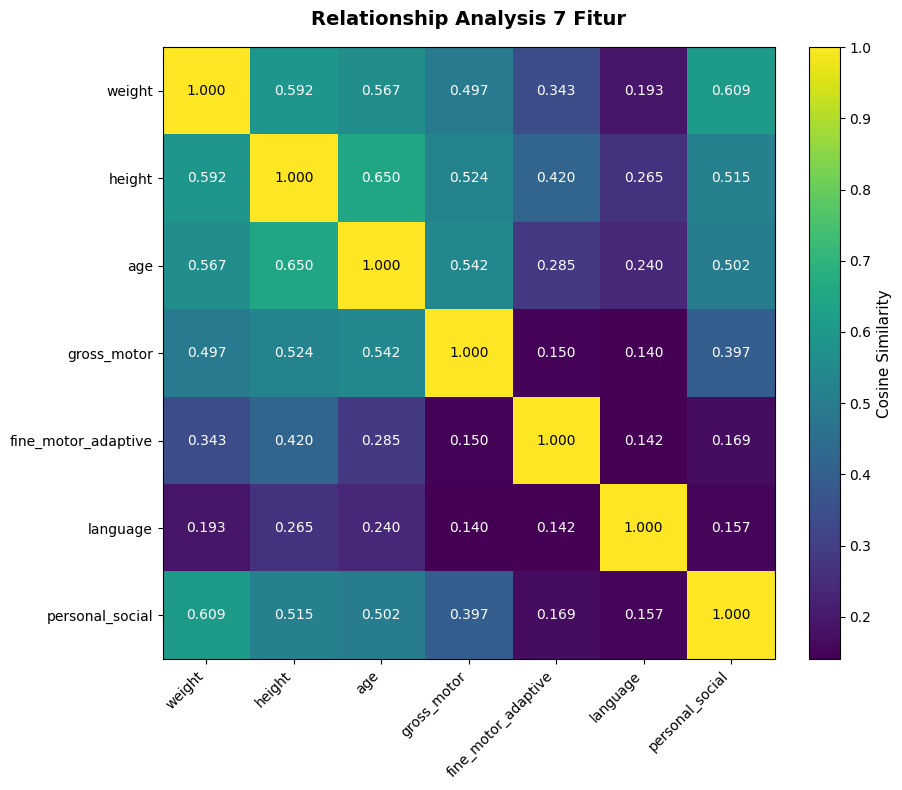

In [17]:

# Visualisasi Relationship Analysis

fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(
    development_similarity_df.values,
    cmap="viridis",
    aspect="equal"
)

# Colorbar
cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

cbar.set_label(
    "Cosine Similarity",
    fontsize=11
)

# Label sumbu X dan Y
ax.set_xticks(
    range(len(DISPLAY_NAMES))
)

ax.set_yticks(
    range(len(DISPLAY_NAMES))
)

ax.set_xticklabels(
    DISPLAY_NAMES,
    rotation=45,
    ha="right",
    fontsize=10
)

ax.set_yticklabels(
    DISPLAY_NAMES,
    fontsize=10
)

# Tampilkan nilai similarity pada setiap sel
for i in range(len(DEVELOPMENT_RELATIONS)):
    for j in range(len(DEVELOPMENT_RELATIONS)):

        value = development_similarity_df.iloc[i, j]

        ax.text(
            j,
            i,
            f"{value:.3f}",
            ha="center",
            va="center",
            color="white" if value < 0.65 else "black",
            fontsize=10
        )

ax.set_title(
    "Relationship Analysis 7 Fitur",
    fontsize=14,
    fontweight="bold",
    pad=16
)

fig.tight_layout()

plt.savefig(
    "../outputs/figures/relationship_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Matriks Korelasi Spearman


,weight,height,age,gross_motor,fine_motor_adaptive,language,personal_social
weight,1.0000,0.0051,-0.0052,-0.0034,0.0115,0.0052,-0.0021
height,0.0051,1.0000,0.0212,-0.0012,-0.0026,0.0062,0.0003
age,-0.0052,0.0212,1.0000,-0.0038,-0.0080,-0.0094,-0.0123
gross_motor,-0.0034,-0.0012,-0.0038,1.0000,-0.0013,0.0016,-0.0045
fine_motor_adaptive,0.0115,-0.0026,-0.0080,-0.0013,1.0000,-0.0030,0.0106
language,0.0052,0.0062,-0.0094,0.0016,-0.0030,1.0000,0.0004
personal_social,-0.0021,0.0003,-0.0123,-0.0045,0.0106,0.0004,1.0000


Matriks P-Value Spearman


,weight,height,age,gross_motor,fine_motor_adaptive,language,personal_social
weight,0.000000,0.517548,0.514534,0.669875,0.145044,0.508029,0.791476
height,0.517548,0.000000,0.007339,0.880790,0.739997,0.435464,0.966169
age,0.514534,0.007339,0.000000,0.632786,0.310829,0.234287,0.119081
gross_motor,0.669875,0.880790,0.632786,0.000000,0.868300,0.838365,0.567185
fine_motor_adaptive,0.145044,0.739997,0.310829,0.868300,0.000000,0.702961,0.181998
language,0.508029,0.435464,0.234287,0.838365,0.702961,0.000000,0.957984
personal_social,0.791476,0.966169,0.119081,0.567185,0.181998,0.957984,0.000000


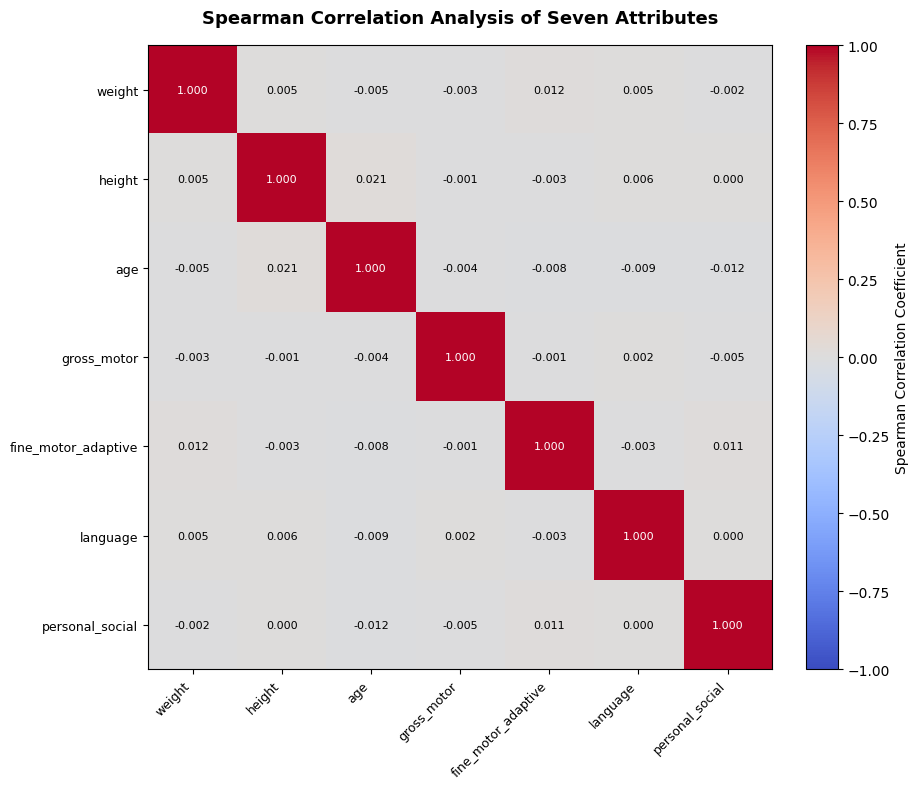

In [18]:

# ==================================================
# ANALISIS KORELASI STATISTIK (SPEARMAN)
# ==================================================

from scipy.stats import spearmanr

# Tujuh fitur asli
ORIGINAL_FEATURES = [
    "weight",
    "height",
    "age",
    "gross_motor",
    "fine_motor_adaptive",
    "language",
    "personal_social"
]

# Ambil tujuh fitur asli dari data TEST
correlation_data = X_test[
    ORIGINAL_FEATURES
].copy()

# Konversi fitur numerik
NUMERIC_FEATURES = [
    "weight",
    "height",
    "age"
]

for column in NUMERIC_FEATURES:
    correlation_data[column] = pd.to_numeric(
        correlation_data[column],
        errors="coerce"
    )

# Pemetaan kategori ordinal domain perkembangan
ORDINAL_MAPPING = {
    "delayed": 1,
    "caution": 2,
    "normal": 3,
    "advanced": 4
}

CATEGORICAL_FEATURES = [
    "gross_motor",
    "fine_motor_adaptive",
    "language",
    "personal_social"
]

# Normalisasi teks dan konversi kategori menjadi angka ordinal
for column in CATEGORICAL_FEATURES:
    correlation_data[column] = (
        correlation_data[column]
        .astype("string")
        .str.strip()
        .str.lower()
        .map(ORDINAL_MAPPING)
    )

# Validasi data
assert correlation_data.notna().all().all(), (
    "Terdapat nilai kosong atau kategori yang tidak dikenali. "
    "Periksa kembali data pada X_test."
)

# Hitung korelasi Spearman
spearman_corr, spearman_pvalue = spearmanr(
    correlation_data
)

# Susun matriks korelasi
spearman_corr_df = pd.DataFrame(
    spearman_corr,
    index=ORIGINAL_FEATURES,
    columns=ORIGINAL_FEATURES
)

# Susun matriks p-value
spearman_pvalue_df = pd.DataFrame(
    spearman_pvalue,
    index=ORIGINAL_FEATURES,
    columns=ORIGINAL_FEATURES
)

print("Matriks Korelasi Spearman")
display(spearman_corr_df.round(4))

print("Matriks P-Value Spearman")
display(spearman_pvalue_df.round(6))

# ==================================================
# VISUALISASI KORELASI SPEARMAN
# ==================================================

fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(
    spearman_corr_df.values,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    aspect="equal"
)

cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

cbar.set_label(
    "Spearman Correlation Coefficient",
    fontsize=10
)

ax.set_xticks(range(len(ORIGINAL_FEATURES)))
ax.set_yticks(range(len(ORIGINAL_FEATURES)))

ax.set_xticklabels(
    ORIGINAL_FEATURES,
    rotation=45,
    ha="right",
    fontsize=9
)

ax.set_yticklabels(
    ORIGINAL_FEATURES,
    fontsize=9
)

# Tampilkan nilai korelasi pada setiap sel
for i in range(len(ORIGINAL_FEATURES)):
    for j in range(len(ORIGINAL_FEATURES)):
        value = spearman_corr_df.iloc[i, j]

        ax.text(
            j,
            i,
            f"{value:.3f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if abs(value) > 0.55 else "black"
        )

ax.set_title(
    "Spearman Correlation Analysis of Seven Attributes",
    fontsize=13,
    fontweight="bold",
    pad=16
)

fig.tight_layout()

plt.savefig(
    "../outputs/figures/spearman_correlation_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [19]:
RELATION_OUTPUT_DIR = Path(
    "../outputs/metrics"
)

RELATION_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

similarity_df.to_csv(
    RELATION_OUTPUT_DIR /
    "relation_similarity_matrix.csv"
)

development_similarity_df.to_csv(
    RELATION_OUTPUT_DIR /
    "development_relationship_analysis.csv"
)

relation_embedding_df.to_csv(
    RELATION_OUTPUT_DIR /
    "relation_embeddings.csv"
)

print("✅ Relationship Analysis berhasil disimpan.")

✅ Relationship Analysis berhasil disimpan.
